# 10 — Figure 4: tropical-mean temperature anomaly cross-sections

Longitude–pressure sections of ΔT = run − control, averaged over 10°S–10°N
(cos-latitude weighted), for FULL (top), UNIFORM (middle) and PATTERN (bottom);
1983 El Niño (left), 1989 La Niña (right). Computed here directly from the
merged ATM output (same calculation as the quick check in `06`).

Drawn at printed width (7 in). Output: `figures/fig4_temp_profile.png` / `.pdf`.

In [1]:
import sys
sys.path.insert(0, "../src")
import config as cfg

import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 8, "font.family": "sans-serif",
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "xtick.labelsize": 7, "ytick.labelsize": 7,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
FIG_WIDTH = 7.0   # inches, full page width in print

EL_NINO_YEAR = 1983
LA_NINA_YEAR = 1989
RUNS = ["FULL", "UNIFORM", "PATTERN"]


def event_dir(event_type):
    return cfg.ECHAM_OUTPUT_ELNINO_DIR if event_type == "El Niño" else cfg.ECHAM_OUTPUT_LANINA_DIR


def tropical_mean_T(path, period=None):
    """Time-mean, 10S-10N cos-weighted temperature (°C) as (plev, lon)."""
    st = xr.open_dataset(path)["st"]
    if period is not None:
        st = st.sel(time=slice(*period))
    st = st.mean("time") - 273.15
    band = st.sel(lat=slice(-10, 10)) if st.lat[0] < st.lat[-1] else st.sel(lat=slice(10, -10))
    weights = np.cos(np.deg2rad(band.lat))
    return band.weighted(weights).mean("lat")

## Step 1 — compute ΔT from the model output

In [2]:
T_clim = tropical_mean_T(cfg.CLIMATOLOGY_ATM_PATH, period=cfg.CLIM_PERIOD)

delta_T = {}
for year, event_type in [(EL_NINO_YEAR, "El Niño"), (LA_NINA_YEAR, "La Niña")]:
    for run in RUNS:
        atm_path = os.path.join(event_dir(event_type), f"{year}_{run}_echam6_ATM_mm_1976-1999.nc")
        if not os.path.exists(atm_path):
            print(f"missing {atm_path} -- skipping")
            continue
        delta_T[(year, run)] = tropical_mean_T(atm_path) - T_clim
        troposphere = delta_T[(year, run)].where(delta_T[(year, run)].plev >= 10000)
        print(f"loaded {year} {run}: max |ΔT| (1000-100 hPa) = {float(abs(troposphere).max()):.2f} °C")

loaded 1983 FULL: max |ΔT| (1000-100 hPa) = 2.12 °C
loaded 1983 UNIFORM: max |ΔT| (1000-100 hPa) = 0.68 °C
loaded 1983 PATTERN: max |ΔT| (1000-100 hPa) = 1.86 °C
loaded 1989 FULL: max |ΔT| (1000-100 hPa) = 1.43 °C
loaded 1989 UNIFORM: max |ΔT| (1000-100 hPa) = 0.96 °C
loaded 1989 PATTERN: max |ΔT| (1000-100 hPa) = 1.03 °C


## Step 2 — draw the 3 × 2 grid

longitude axis: 0.0 to 358.125 °E (192 points)
saved figures/fig4_temp_profile.png
saved figures/fig4_temp_profile.pdf


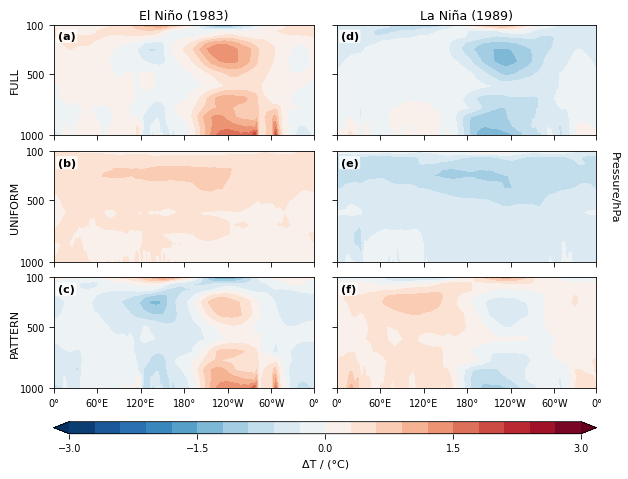

In [3]:
lons = next(iter(delta_T.values())).lon if delta_T else None
if lons is not None:
    print(f"longitude axis: {float(lons[0])} to {float(lons[-1])} °E ({lons.size} points)")
row_names = RUNS
columns = [(EL_NINO_YEAR, "El Niño"), (LA_NINA_YEAR, "La Niña")]
panel_letters = [["a", "d"], ["b", "e"], ["c", "f"]]

VMIN, VMAX = -3, 3
N_LEVELS = 21             # shading boundaries (20 bands)
N_TICKS = 5               # colour bar labels: -3, -1.5, 0, 1.5, 3
P_TOP = 100               # hPa, top of the plotted column
SHOW_LON_LABELS = True    # <- longitude labels under the bottom row
LON_LABELS = ["0°", "60°E", "120°E", "180°", "120°W", "60°W", "0°"]   # last one sits on the last grid point
levels = np.linspace(VMIN, VMAX, N_LEVELS)
cbar_ticks = np.linspace(VMIN, VMAX, N_TICKS)

fig, axes = plt.subplots(3, 2, figsize=(FIG_WIDTH, 5.4), gridspec_kw={"wspace": 0.09, "hspace": 0.14})

cf = None
for col, (year, event_type) in enumerate(columns):
    axes[0, col].set_title(f"{event_type} ({year})", fontsize=9, pad=4)
    for row, run in enumerate(row_names):
        ax = axes[row, col]
        key = (year, run)
        if key in delta_T:
            field = delta_T[key]
            cf = ax.contourf(field.lon, field.plev / 100, field.values, levels=levels, cmap="RdBu_r", extend="both")
            lon_first, lon_last = float(field.lon[0]), float(field.lon[-1])
        else:
            ax.text(0.5, 0.5, "missing data", transform=ax.transAxes, ha="center", va="center", fontsize=8, color="gray")
        ax.set_ylim(1000, P_TOP)   # pressure decreasing upward
        ax.set_yticks([100, 500, 1000])
        if key in delta_T:
            ax.set_xlim(lon_first, lon_last)
            ax.set_xticks([lon_first, 60, 120, 180, 240, 300, lon_last])
            ax.set_xticklabels(LON_LABELS)

        ax.text(0.015, 0.94, f"({panel_letters[row][col]})", transform=ax.transAxes, fontsize=8, fontweight="bold",
                va="top", ha="left", bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8))
        if not (row == 2 and SHOW_LON_LABELS):
            ax.tick_params(labelbottom=False)
        if col == 0:
            ax.text(-0.15, 0.5, run, transform=ax.transAxes, rotation=90, va="center", ha="center", fontsize=8)
        else:
            ax.tick_params(labelleft=False)

if cf is not None:
    cbar = fig.colorbar(cf, ax=axes, orientation="horizontal", fraction=0.045, pad=0.05 if not SHOW_LON_LABELS else 0.08,
                        aspect=45, ticks=cbar_ticks, extendfrac=0.03)
    cbar.set_label("ΔT / (°C)", fontsize=8)   # "ΔT / (°C)"
    cbar.ax.tick_params(labelsize=7, width=0.6)
fig.text(0.925, 0.58, "Pressure/hPa", rotation=270, va="center", ha="center", fontsize=8)

os.makedirs(cfg.FIGURES_DIR, exist_ok=True)
for ext in ["png", "pdf"]:
    out_path = os.path.join(cfg.FIGURES_DIR, f"fig4_temp_profile.{ext}")
    fig.savefig(out_path, dpi=300, bbox_inches="tight")
    print("saved", os.path.relpath(out_path, cfg.REPO_ROOT))
plt.show()